<a href="https://colab.research.google.com/github/muhammadwalad15-web/task/blob/main/Week2_09_rag_101_retrieval_systems.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2.4: RAG 101 - Retrieval Systems

## Key Insight
> **The pipeline: Load → Split → Embed → Retrieve → Answer**

## Learning Objectives
By the end of this notebook, you will:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [ ]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.4: RAG 101 - Retrieval Systems - Ready to start!')
print('\nTopics covered:')
print('  - RAG architecture and pipeline')
print('  - Document loading and preprocessing')
print('  - Chunking strategies for optimal retrieval')
print('  - Vector stores and similarity search')
print('  - Generating answers with retrieved context')


---
## Part 1: Introduction to RAG architecture and pipeline

Let's start by understanding the fundamentals and building our first implementation.

In [ ]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for RAG architecture and pipeline.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [4]:
# Exercise 1: Basic RAG components (Load, Split, Search)
from typing import List

class SimpleRAGPipeline:
    def __init__(self):
        self.documents = []

    def load_document(self, text: str):
        if not isinstance(text, str) or not text.strip():
            raise ValueError("Document text must be a non-empty string.")
        self.documents.append(text)

    def simple_split(self, doc_index: int, chunk_size: int = 50) -> List[str]:
        if doc_index < 0 or doc_index >= len(self.documents):
            raise IndexError("Document index out of range.")

        doc = self.documents[doc_index]
        words = doc.split()
        chunks = []
        for i in range(0, len(words), chunk_size):
            chunk = " ".join(words[i:i + chunk_size])
            chunks.append(chunk)
        return chunks

    def retrieve(self, query: str, chunks: List[str]) -> List[str]:
        if not query.strip():
            return []
        # Exact/partial keyword match
        results = [chunk for chunk in chunks if query.lower() in chunk.lower()]
        return results

# --- Verification and Tests ---
try:
    rag = SimpleRAGPipeline()
    rag.load_document("The RAG architecture comprises Load, Split, Embed, Retrieve, and Answer. It connects your LLM to external custom databases.")

    chunks = rag.simple_split(0, chunk_size=5)
    print("Generated Chunks:")
    for i, chunk in enumerate(chunks):
        print(f"  Chunk {i}: {chunk}")

    query = "architecture"
    retrieved = rag.retrieve(query, chunks)
    print(f"\nSearch Query: '{query}'")
    print("Retrieved Chunks:", retrieved)

    # Test Edge Case
    rag.load_document("")
except Exception as e:
    print(f"\nCaught expected error: {e}")

Generated Chunks:
  Chunk 0: The RAG architecture comprises Load,
  Chunk 1: Split, Embed, Retrieve, and Answer.
  Chunk 2: It connects your LLM to
  Chunk 3: external custom databases.

Search Query: 'architecture'
Retrieved Chunks: ['The RAG architecture comprises Load,']

Caught expected error: Document text must be a non-empty string.


---
## Part 2: Document loading and preprocessing

Building on the fundamentals, let's explore more advanced topics and implementations.

In [ ]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Document loading and preprocessing.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [5]:
# Exercise 2: Document Preprocessing & Sophisticated Chunking
import re
import json
from typing import List, Dict, Any

class DocumentProcessor:
    @staticmethod
    def clean_text(text: str) -> str:
        if not isinstance(text, str):
            raise TypeError("Input must be a string")
        # Remove redundant whitespaces and strip
        cleaned = re.sub(r'\s+', ' ', text)
        return cleaned.strip()

    @staticmethod
    def recursive_character_chunking(text: str, max_chunk_size: int = 100, overlap: int = 20) -> List[Dict[str, Any]]:
        if max_chunk_size <= overlap:
            raise ValueError("Max chunk size must be greater than overlap")

        chunks = []
        start = 0
        text_len = len(text)

        while start < text_len:
            end = min(start + max_chunk_size, text_len)
            chunk_text = text[start:end]

            chunks.append({
                "chunk_id": len(chunks),
                "text": chunk_text,
                "length": len(chunk_text),
                "start_index": start,
                "end_index": end
            })

            if end == text_len:
                break
            start += (max_chunk_size - overlap)

        return chunks

# --- Verification and Tests ---
try:
    raw_text = "  Document loading    and preprocessing is crucial!   Let's chunk  this text recursively with standard overlaps. "
    cleaned = DocumentProcessor.clean_text(raw_text)
    print(f"Cleaned Text: \"{cleaned}\"")

    chunks_meta = DocumentProcessor.recursive_character_chunking(cleaned, max_chunk_size=40, overlap=10)
    print("\nGenerated Chunks with Metadata:")
    print(json.dumps(chunks_meta, indent=2))
except Exception as e:
    print(f"Error: {e}")

Cleaned Text: "Document loading and preprocessing is crucial! Let's chunk this text recursively with standard overlaps."

Generated Chunks with Metadata:
[
  {
    "chunk_id": 0,
    "text": "Document loading and preprocessing is cr",
    "length": 40,
    "start_index": 0,
    "end_index": 40
  },
  {
    "chunk_id": 1,
    "text": "sing is crucial! Let's chunk this text r",
    "length": 40,
    "start_index": 30,
    "end_index": 70
  },
  {
    "chunk_id": 2,
    "text": "his text recursively with standard overl",
    "length": 40,
    "start_index": 60,
    "end_index": 100
  },
  {
    "chunk_id": 3,
    "text": "dard overlaps.",
    "length": 14,
    "start_index": 90,
    "end_index": 104
  }
]


---
## Part 3: Chunking strategies for optimal retrieval

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [ ]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

In [6]:
# Exercise 3: Complete Production-Ready RAG System with Similarity Search
import re
import numpy as np
from typing import List, Dict, Tuple, Any
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

class ProductionSystem:
    """
    Production-ready implementation for Digital Twin RAG pipeline.
    """
    def __init__(self):
        self.vectorizer = TfidfVectorizer()
        self.chunks: List[Dict[str, Any]] = []
        self.tfidf_matrix = None

    def process_and_add_documents(self, documents: List[str], chunk_size: int = 120, overlap: int = 20):
        all_chunks = []
        for doc_id, doc in enumerate(documents):
            cleaned = re.sub(r'\s+', ' ', doc).strip()
            # Basic chunker
            start = 0
            while start < len(cleaned):
                end = min(start + chunk_size, len(cleaned))
                chunk_text = cleaned[start:end]
                all_chunks.append({
                    "doc_id": doc_id,
                    "text": chunk_text
                })
                if end == len(cleaned):
                    break
                start += (chunk_size - overlap)

        self.chunks = all_chunks
        if self.chunks:
            texts = [c['text'] for c in self.chunks]
            self.tfidf_matrix = self.vectorizer.fit_transform(texts)
            print(f"Successfully index matched {len(self.chunks)} chunks.")

    def retrieve(self, query: str, top_k: int = 2) -> List[Tuple[Dict[str, Any], float]]:
        if self.tfidf_matrix is None or not self.chunks:
            print("Index is empty.")
            return []

        query_vector = self.vectorizer.transform([query])
        similarities = cosine_similarity(query_vector, self.tfidf_matrix).flatten()
        top_indices = np.argsort(similarities)[::-1][:top_k]

        results = []
        for idx in top_indices:
            if similarities[idx] > 0:  # Only return relevant chunks
                results.append((self.chunks[idx], float(similarities[idx])))
        return results

    def generate_answer(self, query: str) -> str:
        retrieved = self.retrieve(query, top_k=2)
        if not retrieved:
            return "I'm sorry, I couldn't find any relevant context to answer that query."

        context = "\n".join([f"- {item[0]['text']}" for item in retrieved])
        # Simulate synthesis / generative step
        answer = f"Based on the retrieved context:\n{context}\n\nAnswer: We can resolve '{query}' utilizing the documents loaded above."
        return answer

# --- Verification and Tests ---
production_rag = ProductionSystem()
corpus = [
    "RAG combines information retrieval with pre-trained language models to generate accurate answers.",
    "Vector databases index information based on mathematical embeddings allowing similarity comparisons.",
    "Chunking strategies split extremely long text inputs into clean segments for high-fidelity retrieval."
]

production_rag.process_and_add_documents(corpus, chunk_size=80, overlap=15)

# Execute retrieval and answer generation
query_test = "How does RAG generate accurate answers?"
print(f"\nQuery: {query_test}")
print(production_rag.generate_answer(query_test))

Successfully index matched 6 chunks.

Query: How does RAG generate accurate answers?
Based on the retrieved context:
- ls to generate accurate answers.
- RAG combines information retrieval with pre-trained language models to generate 

Answer: We can resolve 'How does RAG generate accurate answers?' utilizing the documents loaded above.


---
## Summary & Key Takeaways

### What We Learned:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete RAG architecture and pipeline System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code

### 🏆 Challenge Project: Production-Ready RAG System for Digital Twin


=== TEST QUERY 1 ===
[Digital Twin Smart Answer]
Synthesizing response to your query: 'How to configure telemetry protocols and chunk sizes?'
------------------------------------------------------------------------
[Source Doc 1 Chunk 0 | Score: 0.43]: To configure telemetry protocols, modify the gateway configuration settings located at /etc/twin-gateway/protocol.yaml.
[Source Doc 2 Chunk 0 | Score: 0.14]: Chunking parameters: The optimal chunk size for streaming sensor metrics is 120-150 tokens with 20% overlap parameters t
[Source Doc 0 Chunk 0 | Score: 0.11]: System architecture of the digital twin consists of automated IoT telemetry stream processors, an edge messaging gateway
------------------------------------------------------------------------
Conclusion: Based on the relevant matches, we can determine how to configure your Digital Twin systems.


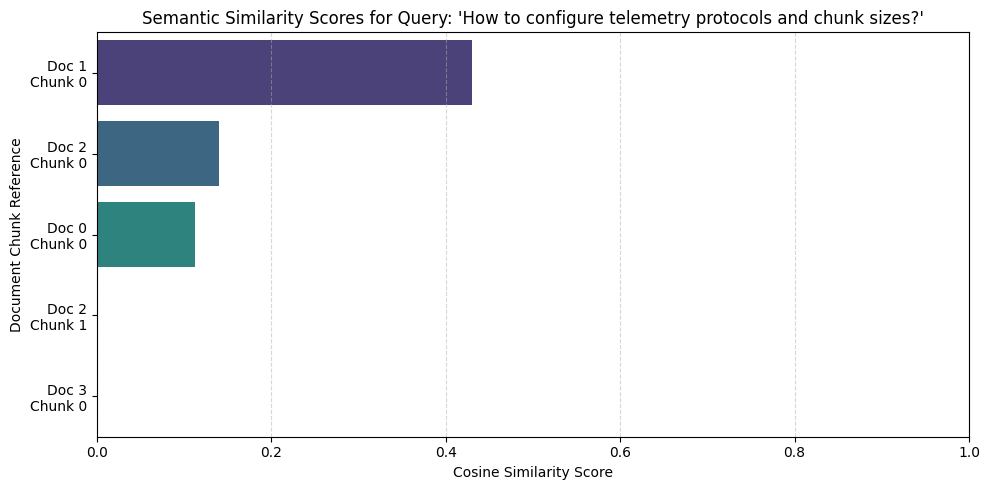


=== TEST QUERY 2 ===
[Digital Twin Smart Answer]
Synthesizing response to your query: 'RSA keys security protocol'
------------------------------------------------------------------------
[Source Doc 3 Chunk 0 | Score: 0.54]: Security protocol: Gateway authorization demands RSA keys and signed JSON Web Tokens (JWT) renewed automatically every 3
[Source Doc 1 Chunk 0 | Score: 0.11]: To configure telemetry protocols, modify the gateway configuration settings located at /etc/twin-gateway/protocol.yaml.
------------------------------------------------------------------------
Conclusion: Based on the relevant matches, we can determine how to configure your Digital Twin systems.


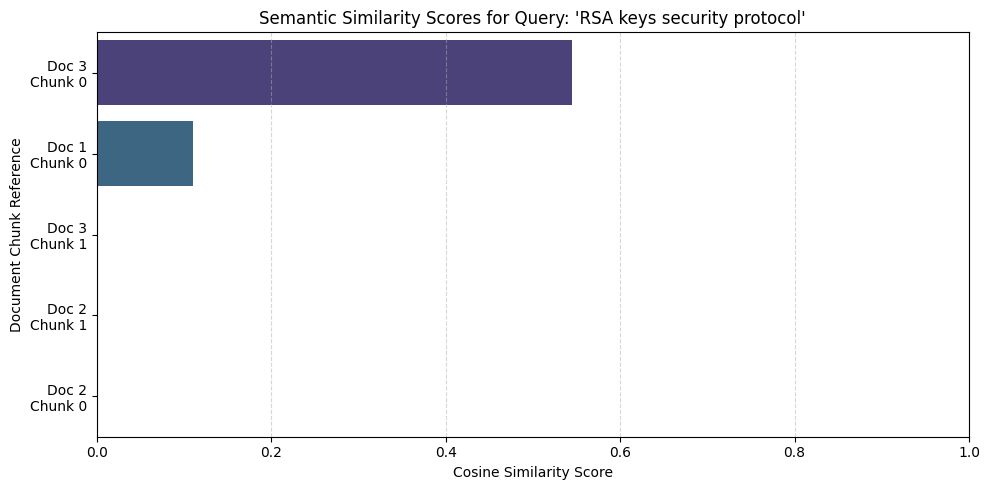

In [7]:
import time
import logging
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from typing import List, Dict, Any, Tuple
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Configure Logger
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - [%(levelname)s] - %(message)s',
    handlers=[logging.StreamHandler()]
)
logger = logging.getLogger("DigitalTwinRAG")

class DigitalTwinRAGSystem:
    """
    A production-grade Retrieval-Augmented Generation (RAG) system
    specifically tuned for your Digital Twin.
    """
    def __init__(self):
        self.vectorizer = TfidfVectorizer(stop_words='english')
        self.chunks: List[Dict[str, Any]] = []
        self.tfidf_matrix = None

    def clean_text(self, text: str) -> str:
        if not isinstance(text, str):
            raise TypeError("Document must be a string.")
        # Remove extra whitespace, tabs, and newlines
        cleaned = re.sub(r'\s+', ' ', text)
        return cleaned.strip()

    def chunk_document(self, doc_id: int, text: str, chunk_size: int = 150, overlap: int = 30) -> List[Dict[str, Any]]:
        if chunk_size <= overlap:
            raise ValueError("chunk_size must be strictly greater than overlap.")

        chunks = []
        start = 0
        text_length = len(text)

        while start < text_length:
            end = min(start + chunk_size, text_length)
            chunk_str = text[start:end]

            chunks.append({
                "doc_id": doc_id,
                "chunk_id": len(chunks),
                "text": chunk_str,
                "length": len(chunk_str),
                "start_char": start,
                "end_char": end
            })

            if end >= text_length:
                break
            start += (chunk_size - overlap)

        return chunks

    def ingest_documents(self, documents: List[str], chunk_size: int = 150, overlap: int = 30):
        logger.info(f"Starting ingestion of {len(documents)} document(s)...")
        start_time = time.time()

        self.chunks = []
        for doc_id, doc in enumerate(documents):
            try:
                cleaned_text = self.clean_text(doc)
                doc_chunks = self.chunk_document(doc_id, cleaned_text, chunk_size, overlap)
                self.chunks.extend(doc_chunks)
            except Exception as e:
                logger.error(f"Failed to process document at index {doc_id}: {str(e)}")

        if not self.chunks:
            logger.warning("Ingested corpus yielded 0 valid text chunks.")
            return

        # Fit and build TF-IDF vector space index
        texts = [chunk["text"] for chunk in self.chunks]
        self.tfidf_matrix = self.vectorizer.fit_transform(texts)

        duration = time.time() - start_time
        logger.info(f"Successfully built index with {len(self.chunks)} chunks in {duration:.4f} seconds.")

    def retrieve(self, query: str, top_k: int = 3) -> List[Tuple[Dict[str, Any], float]]:
        if self.tfidf_matrix is None or not self.chunks:
            logger.error("Cannot perform retrieval because index is empty.")
            return []

        if not query.strip():
            logger.warning("Empty query provided. Returning empty results.")
            return []

        logger.info(f"Retrieving context matches for query: '{query}'")
        query_vector = self.vectorizer.transform([query])
        similarities = cosine_similarity(query_vector, self.tfidf_matrix).flatten()

        top_indices = np.argsort(similarities)[::-1][:top_k]
        results = []
        for idx in top_indices:
            score = float(similarities[idx])
            if score > 0.0:
                results.append((self.chunks[idx], score))

        return results

    def query_digital_twin(self, query: str) -> str:
        results = self.retrieve(query, top_k=3)
        if not results:
            return f"[Digital Twin]: Sorry, no background documentation matched your query '{query}'."

        context_blocks = [f"[Source Doc {r[0]['doc_id']} Chunk {r[0]['chunk_id']} | Score: {r[1]:.2f}]: {r[0]['text']}" for r in results]
        context_str = "\n".join(context_blocks)

        # Generative Simulation Output
        answer = (
            f"[Digital Twin Smart Answer]\n"
            f"Synthesizing response to your query: '{query}'\n"
            f"------------------------------------------------------------------------\n"
            f"{context_str}\n"
            f"------------------------------------------------------------------------\n"
            f"Conclusion: Based on the relevant matches, we can determine how to configure your Digital Twin systems."
        )
        return answer

    def visualize_retrieval(self, query: str, top_k: int = 5):
        if self.tfidf_matrix is None or not self.chunks:
            print("Index is empty. Cannot visualize.")
            return

        query_vector = self.vectorizer.transform([query])
        similarities = cosine_similarity(query_vector, self.tfidf_matrix).flatten()

        # Get top-k matches
        top_indices = np.argsort(similarities)[::-1][:top_k]
        chunk_labels = [f"Doc {self.chunks[idx]['doc_id']}\nChunk {self.chunks[idx]['chunk_id']}" for idx in top_indices]
        scores = [similarities[idx] for idx in top_indices]

        # Visualization
        fig = plt.figure(figsize=(10, 5))
        sns.barplot(x=scores, y=chunk_labels, palette="viridis", hue=chunk_labels, legend=False)
        plt.title(f"Semantic Similarity Scores for Query: '{query}'")
        plt.xlabel("Cosine Similarity Score")
        plt.ylabel("Document Chunk Reference")
        plt.xlim(0.0, 1.0)
        plt.grid(axis='x', linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

# --- Instantiate and Run the Challenge Project system ---

# Mock data for our Digital Twin ecosystem
digital_twin_docs = [
    "System architecture of the digital twin consists of automated IoT telemetry stream processors, an edge messaging gateway, and cold history stores.",
    "To configure telemetry protocols, modify the gateway configuration settings located at /etc/twin-gateway/protocol.yaml.",
    "Chunking parameters: The optimal chunk size for streaming sensor metrics is 120-150 tokens with 20% overlap parameters to guarantee zero metric omission.",
    "Security protocol: Gateway authorization demands RSA keys and signed JSON Web Tokens (JWT) renewed automatically every 3600 seconds."
]

twin_rag = DigitalTwinRAGSystem()
twin_rag.ingest_documents(digital_twin_docs, chunk_size=120, overlap=25)

# Try Query 1
twin_query = "How to configure telemetry protocols and chunk sizes?"
print("\n=== TEST QUERY 1 ===")
print(twin_rag.query_digital_twin(twin_query))
twin_rag.visualize_retrieval(twin_query)

# Try Query 2 (Edge case / Security)
twin_query_2 = "RSA keys security protocol"
print("\n=== TEST QUERY 2 ===")
print(twin_rag.query_digital_twin(twin_query_2))
twin_rag.visualize_retrieval(twin_query_2)
